In [6]:
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

results = np.load("deit_tiny_test_results.npz")

all_labels = results["all_labels"]
all_predictions = results["all_predictions"]
class_names = results["class_names"].tolist()

num_classes = len(class_names)

print("Total data testing:", len(all_labels))
print("Total kelas:", num_classes)

Total data testing: 996
Total kelas: 483


In [7]:
accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(all_labels, all_predictions, average="weighted", zero_division=0)
recall = recall_score(all_labels, all_predictions, average="weighted", zero_division=0)
f1 = f1_score(all_labels, all_predictions, average="weighted", zero_division=0)

print("=" * 40)
print("EVALUASI MODEL DEIT-TINY")
print("=" * 40)

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

EVALUASI MODEL DEIT-TINY
Accuracy  : 0.5633
Precision : 0.5392
Recall    : 0.5633
F1-Score  : 0.5176


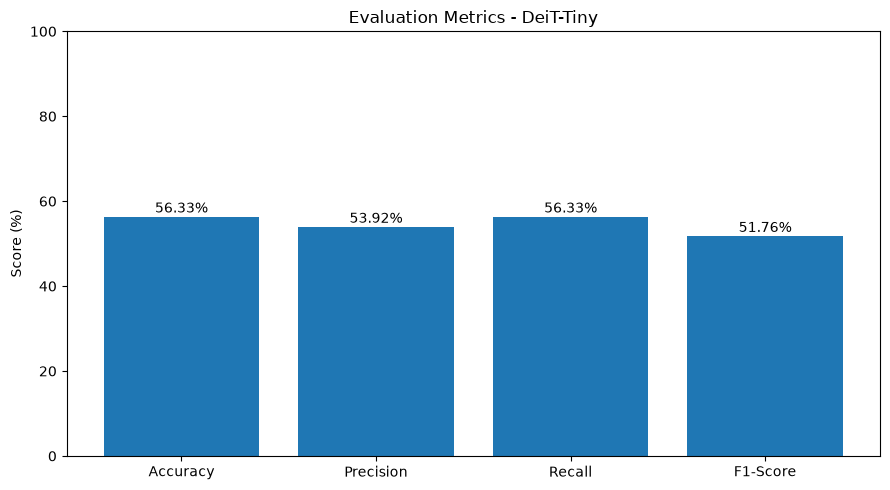

In [8]:
import matplotlib.pyplot as plt

metrics = {
    "Accuracy": accuracy * 100,
    "Precision": precision * 100,
    "Recall": recall * 100,
    "F1-Score": f1 * 100
}

plt.figure(figsize=(9, 5))

bars = plt.bar(metrics.keys(), metrics.values())

plt.title("Evaluation Metrics - DeiT-Tiny")
plt.ylabel("Score (%)")
plt.ylim(0, 100)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{bar.get_height():.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [9]:
import pandas as pd
from sklearn.metrics import classification_report

report = classification_report(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names))),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

df_report = pd.DataFrame(report).T

# Ambil hanya baris kelas, bukan accuracy atau rata-rata
df_classes = df_report.iloc[:len(class_names)].copy()

# Urutkan berdasarkan F1-score terendah
df_classes = df_classes.sort_values("f1-score")

print("10 KELAS DENGAN PERFORMA TERENDAH")
display(df_classes.head(10).round(4))

print("\n10 KELAS DENGAN PERFORMA TERTINGGI")
display(df_classes.tail(10).sort_values("f1-score", ascending=False).round(4))

10 KELAS DENGAN PERFORMA TERENDAH


,precision,recall,f1-score,support
zenarchopterus_dispar,0.0,0.0,0.0,1.0
alectis_ciliaris,0.0,0.0,0.0,1.0
alectis_indica,0.0,0.0,0.0,1.0
anampses_elegans,0.0,0.0,0.0,2.0
anampses_melanurus,0.0,0.0,0.0,2.0
anampses_femininus,0.0,0.0,0.0,1.0
anampses_twistii,0.0,0.0,0.0,2.0
anodontostoma_chacunda,0.0,0.0,0.0,2.0
thysanophrys_celebica,0.0,0.0,0.0,1.0
symphorus_nematophorus,0.0,0.0,0.0,1.0



10 KELAS DENGAN PERFORMA TERTINGGI


,precision,recall,f1-score,support
scolopsis_trilineata,1.0,1.0,1.0,1.0
serranocirrhitus_latus,1.0,1.0,1.0,2.0
thalassoma_lutescens,1.0,1.0,1.0,4.0
thryssa_baelama,1.0,1.0,1.0,2.0
anampses_lennardi,1.0,1.0,1.0,2.0
anampses_meleagrides,1.0,1.0,1.0,3.0
anampses_neoguinaicus,1.0,1.0,1.0,1.0
amanses_scopas,1.0,1.0,1.0,4.0
alepes_kleinii,1.0,1.0,1.0,1.0
zeus_faber,1.0,1.0,1.0,2.0


In [10]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# Confusion matrix seluruh kelas
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(num_classes))
)

# Hitung TP, TN, FP, FN menggunakan One-vs-Rest
TP = np.diag(cm)
FP = cm.sum(axis=0) - TP
FN = cm.sum(axis=1) - TP
TN = cm.sum() - (TP + FP + FN)

# Buat tabel evaluasi
df_confusion = pd.DataFrame({
    "Class": class_names,
    "True Positive (TP)": TP,
    "True Negative (TN)": TN,
    "False Positive (FP)": FP,
    "False Negative (FN)": FN
})

print("=" * 70)
print("PERHITUNGAN TP, TN, FP, FN - DEIT-TINY")
print("=" * 70)

display(df_confusion)

# Total seluruh kelas
print("\nTOTAL HASIL PERHITUNGAN")
print("True Positive  :", TP.sum())
print("True Negative  :", TN.sum())
print("False Positive :", FP.sum())
print("False Negative :", FN.sum())

PERHITUNGAN TP, TN, FP, FN - DEIT-TINY


,Class,True Positive (TP),True Negative (TN),False Positive (FP),False Negative (FN)
0,A73EGS-P,1,994,0,1
1,CUNWCB-Y,1,994,0,1
2,Istiophorus_platypterus,1,993,2,0
3,P1ROZC-Z,2,992,0,2
4,PQV7DP-S,0,994,0,2
...,...,...,...,...,...
478,wetmorella_albofasciata,1,995,0,0
479,wetmorella_nigropinnata,2,992,1,1
480,xiphocheilus_typus,2,990,4,0
481,zenarchopterus_dispar,0,995,0,1



TOTAL HASIL PERHITUNGAN
True Positive  : 561
True Negative  : 479637
False Positive : 435
False Negative : 435


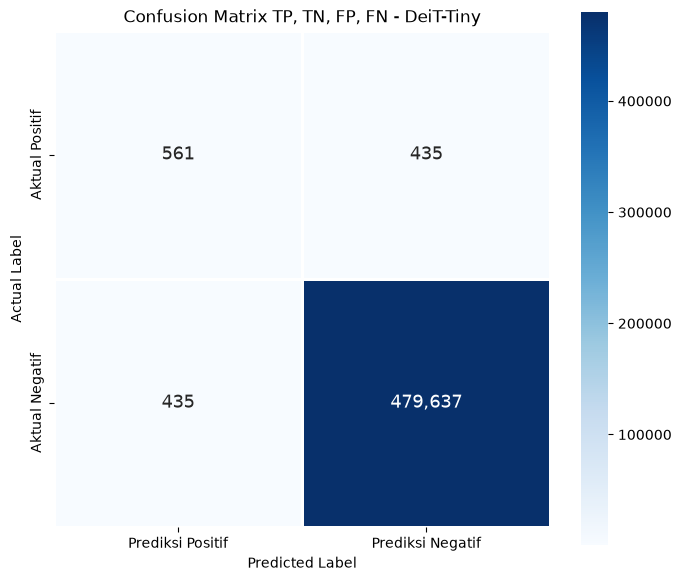

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Matriks gabungan One-vs-Rest seluruh kelas
matrix_2x2 = np.array([
    [TP.sum(), FN.sum()],
    [FP.sum(), TN.sum()]
])

plt.figure(figsize=(7, 6))

sns.heatmap(
    matrix_2x2,
    annot=True,
    fmt=",",
    cmap="Blues",
    square=True,
    linewidths=2,
    cbar=True,
    xticklabels=["Prediksi Positif", "Prediksi Negatif"],
    yticklabels=["Aktual Positif", "Aktual Negatif"],
    annot_kws={"size": 13}
)

plt.title("Confusion Matrix TP, TN, FP, FN - DeiT-Tiny")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()